# Projet F1 : prédire le risque de crédit en Allemagne (UCI 144)

**Cours BD & DS · ENCG Settat · S7 · Science des données appliquée à la finance** · Examen CC Partie B
**Algorithme principal :** régression logistique (algorithme 8 du support) · comparée à un arbre de décision et à une forêt aléatoire · **Données :** UCI Statlog (German Credit Data)

Ce notebook suit l'ordre du rapport : introduction, état de l'art, travaux liés, données, exploration, préparation, algorithme, protocole, résultats, discussion, conclusion, références et annexes. Il télécharge lui-même les données : il suffit de lancer **Exécution > Tout exécuter** (environ 1 minute).

> **À propos des chiffres commentés.** Toutes les interprétations chiffrées (sections 10 et 11) sont **générées par le code à partir de votre exécution** : elles ne peuvent donc pas contredire les tableaux. Les seuls chiffres écrits à la main sont des faits du jeu de données (1 000 dossiers, 300 mauvais risques, matrice de coûts 1 / 5).

**Sommaire**
0. Configuration
1. Introduction
2. État de l'art
3. Travaux liés
4. Jeu de données
5. Exploration
6. Préparation
7. Algorithme
8. Protocole expérimental
9. Résultats
10. Discussion des résultats
11. Conclusion
12. Références et citations
13. Annexes

## 0. Configuration

In [2]:
import platform, json, zipfile, shutil, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, roc_curve
from sklearn.inspection import permutation_importance

GRAINE = 42
BASE = Path('projet_f1_credit')
DONNEES = BASE / 'data' / 'raw'
FIGURES = BASE / 'figures'
for dossier in (DONNEES, FIGURES):
    dossier.mkdir(parents=True, exist_ok=True)

# Matrice de coûts de la documentation du jeu (german.doc) : refuser un bon client coûte 1,
# accepter un mauvais client coûte 5. Classe positive = mauvais risque (1).
COUT_FP, COUT_FN = 1, 5

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 9})

def fr(x, d=1):
    """Nombre au format français (virgule décimale)."""
    return '{:.{d}f}'.format(x, d=d).replace('.', ',')

def cout(y_vrai, y_pred, c_fp=COUT_FP, c_fn=COUT_FN):
    """Coût total des erreurs : c_fp x faux positifs + c_fn x faux négatifs."""
    tn, fp, fn, tp = confusion_matrix(y_vrai, y_pred, labels=[0, 1]).ravel()
    return c_fp * fp + c_fn * fn

SEUILS = np.round(np.arange(0.01, 1.00, 0.01), 2)   # une seule grille de seuils pour tout le notebook

def courbe_cout(y_vrai, proba, c_fn=COUT_FN, c_fp=COUT_FP):
    y_vrai = np.asarray(y_vrai)
    return np.array([cout(y_vrai, (proba >= s).astype(int), c_fp, c_fn) for s in SEUILS])

def meilleur_seuil(y_vrai, proba, c_fn=COUT_FN, c_fp=COUT_FP):
    """Seuil de coût minimal (au milieu du plateau en cas d'égalité, pour limiter le bruit)."""
    c = courbe_cout(y_vrai, proba, c_fn, c_fp)
    idx = np.flatnonzero(c == c.min())
    return float(SEUILS[idx[len(idx) // 2]])

R = {}  # tous les résultats chiffrés, enregistrés à la fin
print('Python', platform.python_version(), '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Python 3.13.18 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0


## 1. Introduction

**Contexte.** Accorder un crédit est une activité centrale pour une banque, mais elle comporte un risque : un client qui ne rembourse pas provoque une perte. Le jeu *German Credit Data* décrit 1 000 dossiers de crédit à des particuliers, dont 300 ont été classés « mauvais risque ». Prédire le risque *avant* la décision aide l'analyste crédit à accepter ou refuser un dossier.

**Problématique.** À partir des seules informations du dossier (profil du client et caractéristiques du prêt), peut-on décider d'accepter ou de refuser un crédit à un coût d'erreurs plus faible qu'avec une règle simple, sachant qu'accepter un mauvais client coûte cinq fois plus que refuser un bon client ?

**Objectif mesurable.** Sur le jeu de test (20 % des dossiers, mis de côté dès le départ), obtenir un coût total des erreurs inférieur d'au moins 10 % (en relatif) à celui de la meilleure référence naïve (« accepter tous les dossiers » ou « refuser tous les dossiers »).

**Nature du problème.** Classification binaire (30 % de mauvais risques) **à coûts asymétriques** : la qualité du modèle se juge d'abord par son coût financier, pas par sa précision globale. Avec 70 % de bons clients, un modèle qui accepterait tout le monde aurait 70 % de bonnes réponses mais un coût très élevé : l'*accuracy* est donc trompeuse ici [7].

## 2. État de l'art

Le *credit scoring* attribue à chaque demandeur un score de risque, puis fixe un seuil au-delà duquel le dossier est refusé. La régression logistique est la référence statistique de ce type de score [4]. Les arbres de décision [5] produisent des règles lisibles ; les forêts aléatoires [6] moyennent de nombreux arbres et captent des relations non linéaires. Quand les erreurs n'ont pas le même coût, le seuil de décision doit être choisi selon ce coût : pour des probabilités bien calibrées, on refuse un dossier dès que la probabilité de défaut dépasse $c_{FP}/(c_{FP}+c_{FN})$ [7]. Avec une matrice 1 / 5, ce seuil théorique vaut 1/6, soit environ 0,17, et non 0,5.

| Approche | Principe | Atouts | Limites | Réf. |
| --- | --- | --- | --- | --- |
| Règle naïve | Accepter (ou refuser) tous les dossiers | Aucun calcul | Ignore le profil du client | Cette étude |
| Régression logistique | Combinaison linéaire des variables, transformée en probabilité | Interprétable, robuste, rapide | Effets linéaires sur la log-cote | [4] |
| Arbre de décision | Série de questions oui/non sur les variables | Règles lisibles | Instable, surapprend vite | [5] |
| Forêt aléatoire | Moyenne de nombreux arbres entraînés sur des échantillons différents | Non-linéarités, interactions | Moins interprétable | [6] |
| Seuil sensible aux coûts | Choisir le seuil qui minimise le coût total | Adapte la décision à l'enjeu financier | Dépend des coûts supposés | [7] |

## 3. Travaux liés

| Travail | Données | Méthode | Résultat principal | Différence avec cette étude |
| --- | --- | --- | --- | --- |
| Baesens *et al.*, 2003 [2] | Huit jeux de crédit, dont *German Credit* | Comparaison de nombreux classifieurs (régression logistique, arbres, réseaux de neurones, SVM) | Les méthodes non linéaires les plus flexibles se distinguent un peu, mais la régression logistique reste très compétitive | Nous évaluons un seul jeu, avec un coût asymétrique et un seuil optimisé |
| Lessmann *et al.*, 2015 [3] | Plusieurs jeux de crédit, dont des jeux publics | Mise à jour du comparatif de 2003 avec davantage de méthodes, dont des ensembles | Les méthodes d'ensemble classent en moyenne mieux que les classifieurs individuels | Trois modèles seulement ; évaluation par le coût et non par un classement moyen |

**Positionnement.** Comme ces travaux, nous comparons une référence linéaire (régression logistique) à des modèles plus flexibles (arbre, forêt). Contrairement à une simple comparaison d'AUC, nous jugeons les modèles par leur **coût financier** avec la matrice de coûts de la documentation du jeu, et nous choisissons le seuil de décision sans utiliser le jeu de test. Avec 1 000 dossiers seulement, nos résultats ne sont pas directement comparables à ceux de ces études.

## 4. Jeu de données

### 4.1 Téléchargement depuis l'UCI Machine Learning Repository

In [3]:
URL = 'https://archive.ics.uci.edu/static/public/144/statlog+german+credit+data.zip'
fichier = DONNEES / 'german.data'
ancien_zip = Path('/content/statlog+german+credit+data (1).zip')   # archive téléversée à la main (ancienne méthode)
if not fichier.exists():
    try:
        if ancien_zip.exists():
            archive = ancien_zip
        else:
            archive = DONNEES / 'german_credit.zip'
            urllib.request.urlretrieve(URL, archive)
        with zipfile.ZipFile(archive) as z:
            for nom in ('german.data', 'german.doc'):
                if nom in z.namelist():
                    z.extract(nom, DONNEES)
        if archive.parent == DONNEES:
            archive.unlink()
        print('Données prêtes dans', DONNEES)
    except Exception as erreur:
        print('Téléchargement impossible :', erreur)
        print('Téléversez german.data dans', DONNEES, '(menu Fichiers à gauche), puis relancez cette cellule.')
else:
    print('Données déjà présentes :', fichier)

Données prêtes dans projet_f1_credit/data/raw


In [4]:
COLONNES = ['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status',
            'employment', 'installment_rate', 'personal_status', 'other_parties', 'residence_since',
            'property_magnitude', 'age', 'other_payment_plans', 'housing', 'existing_credits', 'job',
            'num_dependents', 'own_telephone', 'foreign_worker', 'class']
df = pd.read_csv(DONNEES / 'german.data', sep=' ', header=None, names=COLONNES)
print('Dimensions :', df.shape)
df.head()

Dimensions : (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [5]:
df.dtypes.to_frame('type').T

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
type,object,int64,object,object,int64,object,object,int64,object,object,...,object,int64,object,object,int64,object,int64,object,object,int64


### 4.2 Description

- **Nom et source :** « Statlog (German Credit Data) », UCI Machine Learning Repository, jeu n° 144 [1], fichier `german.data`, https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data
- **Date d'extraction :** 24/11/2026 · **Licence :** CC BY 4.0
- **Taille :** 1 000 observations, 20 variables explicatives (7 numériques, 13 catégorielles) et la cible `class`
- **Unité d'observation :** un dossier de crédit d'un particulier
- **Variable cible :** `class` (1 = bon risque, 2 = mauvais risque). Elle est recodée en `cible` : **1 = mauvais risque**, classe à détecter ; 700 bons dossiers et 300 mauvais
- **Matrice de coûts (documentation du jeu) :** refuser un bon client coûte 1 ; accepter un mauvais client coûte 5
- **Adéquation :** le jeu décrit le client et le prêt au moment de la demande, donc connus avant la décision ; il est petit et équilibré à 70/30, ce qui se prête à une validation croisée
- **Limites :** seulement 1 000 dossiers (un test de 200 dossiers ne contient que 60 mauvais risques) ; données anciennes d'une banque allemande ; les coûts 1 / 5 sont une hypothèse du jeu, pas ceux d'une banque réelle ; la variable `personal_status` mêle sexe et situation familiale, et `foreign_worker` et `age` sont des variables sensibles (voir la section 10)

### 4.3 Dictionnaire des variables

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
| --- | --- | --- | --- | --- | --- |
| `class` → `cible` | 1 si mauvais risque (classe 2 d'origine) | binaire | | cible | 0 |
| `checking_status` | Situation du compte courant | catégorielle | | explicative | 0 |
| `duration` | Durée du crédit | numérique | mois | explicative | 0 |
| `credit_history` | Historique de crédit | catégorielle | | explicative | 0 |
| `purpose` | Objet du crédit | catégorielle | | explicative | 0 |
| `credit_amount` | Montant du crédit | numérique | DM | explicative | 0 |
| `savings_status` | Épargne et obligations | catégorielle | | explicative | 0 |
| `employment` | Ancienneté dans l'emploi actuel | catégorielle | | explicative | 0 |
| `installment_rate` | Mensualité en % du revenu disponible | numérique (1 à 4) | % | explicative | 0 |
| `personal_status` | Situation familiale et sexe | catégorielle | | explicative (sensible) | 0 |
| `other_parties` | Autres débiteurs ou garants | catégorielle | | explicative | 0 |
| `residence_since` | Ancienneté de résidence | numérique (1 à 4) | | explicative | 0 |
| `property_magnitude` | Patrimoine le plus important | catégorielle | | explicative | 0 |
| `age` | Âge | numérique | années | explicative (sensible) | 0 |
| `other_payment_plans` | Autres plans de paiement | catégorielle | | explicative | 0 |
| `housing` | Logement | catégorielle | | explicative | 0 |
| `existing_credits` | Nombre de crédits dans cette banque | numérique | crédits | explicative | 0 |
| `job` | Emploi | catégorielle | | explicative | 0 |
| `num_dependents` | Personnes à charge | numérique | personnes | explicative | 0 |
| `own_telephone` | Téléphone au nom du client | catégorielle | | explicative | 0 |
| `foreign_worker` | Travailleur étranger | catégorielle | | explicative (sensible) | 0 |

Les modalités catégorielles gardent les codes d'origine (`A11`, `A12`, …) décrits dans `german.doc`. Aucune variable n'est exclue : toutes sont connues au moment de la décision.

## 5. Exploration

### 5.1 Qualité des données

In [6]:
df['cible'] = (df['class'] == 2).astype(int)      # 1 = mauvais risque
R['n'] = int(len(df))
R['doublons'] = int(df.drop(columns=['class', 'cible']).duplicated().sum())
R['nan'] = int(df.isna().sum().sum())
R['n_mauvais'] = int(df['cible'].sum())
R['taux_mauvais'] = float(df['cible'].mean())
print('Dossiers :', R['n'], '| doublons :', R['doublons'], '| valeurs manquantes :', R['nan'])
print('Mauvais risques : {} ({} %)'.format(R['n_mauvais'], fr(R['taux_mauvais'] * 100)))
print('Modalités par variable catégorielle :', df.select_dtypes(exclude='number').nunique().to_dict())
df[['duration', 'credit_amount', 'installment_rate', 'age', 'existing_credits']].describe().T.round(1)

Dossiers : 1000 | doublons : 0 | valeurs manquantes : 0
Mauvais risques : 300 (30,0 %)
Modalités par variable catégorielle : {'checking_status': 4, 'credit_history': 5, 'purpose': 10, 'savings_status': 5, 'employment': 5, 'personal_status': 4, 'other_parties': 3, 'property_magnitude': 4, 'other_payment_plans': 3, 'housing': 3, 'job': 4, 'own_telephone': 2, 'foreign_worker': 2}


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.9,12.1,4.0,12.0,18.0,24.0,72.0
credit_amount,1000.0,3271.3,2822.7,250.0,1365.5,2319.5,3972.2,18424.0
installment_rate,1000.0,3.0,1.1,1.0,2.0,3.0,4.0,4.0
age,1000.0,35.5,11.4,19.0,27.0,33.0,42.0,75.0
existing_credits,1000.0,1.4,0.6,1.0,1.0,1.0,2.0,4.0


**Lecture.** Le jeu ne contient ni valeur manquante ni doublon : aucune ligne n'est supprimée. La cible est déséquilibrée (70 % / 30 %), d'où l'usage de découpages **stratifiés** (même proportion de mauvais risques dans chaque ensemble) et d'une évaluation par le coût. Les montants sont très asymétriques (quelques gros crédits) : ils sont conservés, car ce sont des dossiers réels.

### 5.2 Graphiques

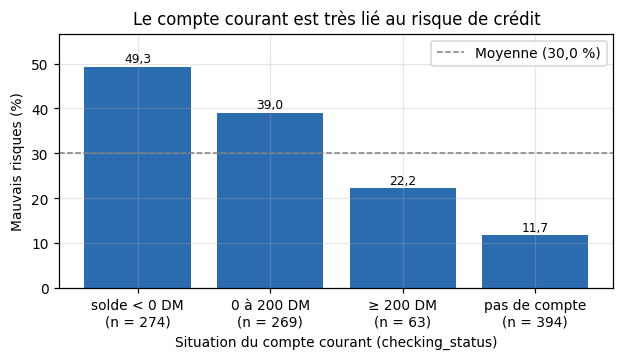

In [7]:
# Figure 1 : taux de mauvais risques selon la situation du compte courant
noms_cpt = {'A11': 'solde < 0 DM', 'A12': '0 à 200 DM', 'A13': '≥ 200 DM', 'A14': 'pas de compte'}
t = df.groupby('checking_status')['cible'].agg(['mean', 'size']).loc[list(noms_cpt)]
R['taux_compte'] = {k: round(float(t.loc[k, 'mean']) * 100, 1) for k in noms_cpt}
fig, ax = plt.subplots(figsize=(6.5, 3))
etiq = ['{}\n(n = {})'.format(noms_cpt[k], t.loc[k, 'size']) for k in noms_cpt]
ax.bar(etiq, t['mean'] * 100, color='#2b6cb0')
ax.axhline(R['taux_mauvais'] * 100, ls='--', color='grey', lw=1, label='Moyenne ({} %)'.format(fr(R['taux_mauvais'] * 100)))
for i, v in enumerate(t['mean'] * 100):
    ax.text(i, v + 1, fr(v), ha='center', fontsize=8)
ax.set_ylim(0, t['mean'].max() * 100 * 1.15)
ax.set_xlabel('Situation du compte courant (checking_status)')
ax.set_ylabel('Mauvais risques (%)')
ax.set_title('Le compte courant est très lié au risque de crédit')
ax.legend(loc='upper right')
fig.savefig(FIGURES / 'fig1_compte_courant.png', dpi=200, bbox_inches='tight')
plt.show()

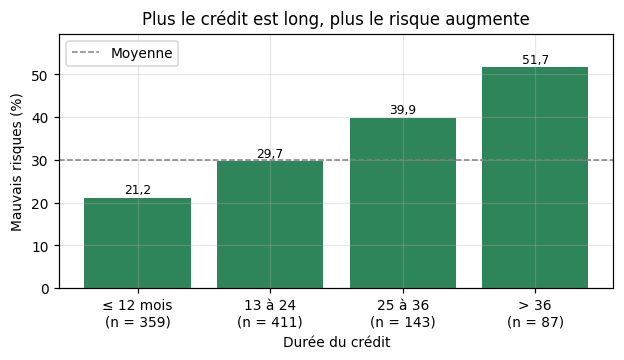

In [8]:
# Figure 2 : taux de mauvais risques selon la durée du crédit
tranches = pd.cut(df['duration'], [0, 12, 24, 36, 100], labels=['≤ 12 mois', '13 à 24', '25 à 36', '> 36'])
t2 = df.groupby(tranches, observed=True)['cible'].agg(['mean', 'size'])
R['taux_duree'] = {str(k): round(float(v) * 100, 1) for k, v in t2['mean'].items()}
fig, ax = plt.subplots(figsize=(6.5, 3))
etiq = ['{}\n(n = {})'.format(k, n) for k, n in zip(t2.index, t2['size'])]
ax.bar(etiq, t2['mean'] * 100, color='#2f855a')
ax.axhline(R['taux_mauvais'] * 100, ls='--', color='grey', lw=1, label='Moyenne')
for i, v in enumerate(t2['mean'] * 100):
    ax.text(i, v + 1, fr(v), ha='center', fontsize=8)
ax.set_ylim(0, t2['mean'].max() * 100 * 1.15)
ax.set_xlabel('Durée du crédit'); ax.set_ylabel('Mauvais risques (%)')
ax.set_title('Plus le crédit est long, plus le risque augmente')
ax.legend(loc='upper left')
fig.savefig(FIGURES / 'fig2_duree.png', dpi=200, bbox_inches='tight')
plt.show()

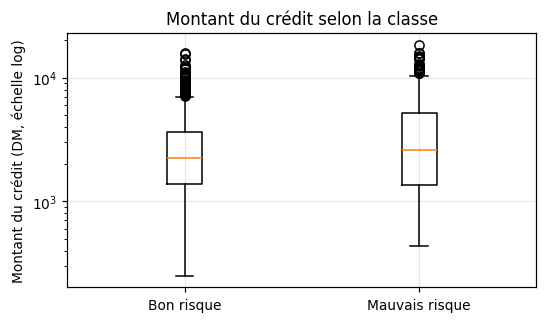

Montant médian (DM) : bons 2244 | mauvais 2574


In [9]:
# Figure complémentaire : montant du crédit selon la classe
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.boxplot([df.loc[df['cible'] == 0, 'credit_amount'], df.loc[df['cible'] == 1, 'credit_amount']])
ax.set_xticks([1, 2]); ax.set_xticklabels(['Bon risque', 'Mauvais risque'])
ax.set_yscale('log'); ax.set_ylabel('Montant du crédit (DM, échelle log)')
ax.set_title('Montant du crédit selon la classe')
fig.savefig(FIGURES / 'figA_montant.png', dpi=200, bbox_inches='tight')
plt.show()
R['montant_median'] = {'bon': float(df.loc[df['cible'] == 0, 'credit_amount'].median()),
                       'mauvais': float(df.loc[df['cible'] == 1, 'credit_amount'].median())}
print('Montant médian (DM) : bons {:.0f} | mauvais {:.0f}'.format(R['montant_median']['bon'], R['montant_median']['mauvais']))

**Lecture des figures.** Le risque dépend nettement de la situation du compte courant (figure 1) : les clients à découvert ou avec un petit solde sont beaucoup plus souvent de mauvais risques que ceux sans compte ou avec un solde élevé. Le risque augmente aussi avec la durée du crédit (figure 2), et les mauvais dossiers portent en général sur des montants plus élevés (figure complémentaire). Ce sont des associations, pas des causes. Les valeurs exactes sont écrites sur les graphiques et enregistrées dans `resultats.json`.

## 6. Préparation

In [10]:
X = df.drop(columns=['class', 'cible'])
y = df['cible']
NUM = X.select_dtypes('number').columns.tolist()
CAT = X.select_dtypes(exclude='number').columns.tolist()
print(len(NUM), 'variables numériques :', NUM)
print(len(CAT), 'variables catégorielles :', CAT)

# Le jeu de test est mis de côté dès maintenant et n'est utilisé qu'une seule fois, à la section 9
X_app, X_test, y_app, y_test = train_test_split(X, y, test_size=0.20, random_state=GRAINE, stratify=y)
R['n_app'], R['n_test'] = len(X_app), len(X_test)
R['mauvais_app'], R['mauvais_test'] = int(y_app.sum()), int(y_test.sum())
print('Apprentissage : {} dossiers dont {} mauvais ({} %)'.format(R['n_app'], R['mauvais_app'], fr(y_app.mean() * 100)))
print('Test          : {} dossiers dont {} mauvais ({} %)'.format(R['n_test'], R['mauvais_test'], fr(y_test.mean() * 100)))

7 variables numériques : ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']
13 variables catégorielles : ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']
Apprentissage : 800 dossiers dont 240 mauvais (30,0 %)
Test          : 200 dossiers dont 60 mauvais (30,0 %)


In [11]:
# Pipelines : encodage et standardisation sont ajustés sur l'apprentissage seulement, dans chaque pli
def preparation(echelle):
    return ColumnTransformer([('num', StandardScaler() if echelle else 'passthrough', NUM),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])

modeles = {
    'lr': Pipeline([('prep', preparation(True)), ('modele', LogisticRegression(max_iter=3000))]),
    'dt': Pipeline([('prep', preparation(False)), ('modele', DecisionTreeClassifier(random_state=GRAINE))]),
    'rf': Pipeline([('prep', preparation(False)),
                    ('modele', RandomForestClassifier(n_estimators=300, random_state=GRAINE, n_jobs=-1))])}
libelles = {'lr': 'Régression logistique', 'dt': 'Arbre de décision', 'rf': 'Forêt aléatoire'}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)   # validation croisée stratifiée, dans l'apprentissage
nb_colonnes = modeles['lr'].fit(X_app, y_app).named_steps['prep'].transform(X_app).shape[1]
print('Colonnes après encodage :', nb_colonnes)
print('Plis de validation (apprentissage, validation) :', [(len(a), len(v)) for a, v in cv.split(X_app, y_app)])

Colonnes après encodage : 61
Plis de validation (apprentissage, validation) : [(640, 160), (640, 160), (640, 160), (640, 160), (640, 160)]


**Choix de préparation.**

1. **Nettoyage :** aucune ligne supprimée (pas de valeur manquante, pas de doublon) ; valeurs extrêmes conservées.
2. **Variables :** les 20 variables sont gardées ; la cible est recodée (1 = mauvais risque).
3. **Encodage :** *one-hot* pour les 13 variables catégorielles ; standardisation des 7 variables numériques pour la régression logistique seulement (inutile pour les arbres et les forêts).
4. **Découpage :** 80 % pour l'apprentissage (800 dossiers) et 20 % pour le test (200 dossiers), **stratifié** sur la cible. La validation se fait **dans** l'apprentissage, par validation croisée stratifiée à 5 plis. Ce choix remplace un unique découpage de 200 dossiers de validation, trop petit (environ 60 mauvais risques) pour comparer des coûts de façon fiable.

**Prévention des fuites.**

- ✔ Test mis de côté avant toute analyse de modèle, utilisé une seule fois, à la fin.
- ✔ Encodage et standardisation ajustés sur l'apprentissage seulement, dans un `Pipeline` (donc dans chaque pli de la validation croisée).
- ✔ Hyperparamètres et seuil de décision choisis par validation croisée, jamais sur le test.
- ✔ Aucune variable ne contient la cible ; toutes sont connues avant la décision.

## 7. Algorithme

**Choix.** Algorithme principal : la **régression logistique** (algorithme 8 du support, `LogisticRegression` [9]). Elle fournit directement une probabilité de défaut, elle est interprétable (chaque coefficient indique le sens d'un effet) et c'est la référence du *credit scoring* [4]. Un arbre de décision (algorithme du support) et une forêt aléatoire servent de comparaison. Le modèle final est celui dont le **coût de validation** est le plus faible (section 8), pas celui dont l'AUC de test serait la plus haute.

**Principe.** La régression logistique estime la probabilité qu'un dossier soit un mauvais risque par :

$$\hat{p}(x) = \frac{1}{1 + e^{-(\beta_0 + \beta^\top x)}}$$

où $x$ est le vecteur des variables du dossier (après encodage et standardisation), $\beta_0$ la constante, $\beta$ le vecteur des coefficients et $\hat{p}(x)$ la probabilité estimée de défaut. Les coefficients sont appris en minimisant la perte logistique avec une pénalité $\ell_2$ de force $1/C$ [4]. Un dossier est refusé si $\hat{p}(x) \geq s$, où $s$ est le **seuil de décision**.

**Seuil optimal théorique.** Refuser un bon client coûte $c_{FP} = 1$ et accepter un mauvais client coûte $c_{FN} = 5$. Pour une probabilité bien calibrée, refuser est rentable dès que $\hat{p}\, c_{FN} \geq (1-\hat{p})\, c_{FP}$, soit $s^* = c_{FP}/(c_{FP}+c_{FN}) = 1/6 \approx 0{,}17$ [7]. Ce seuil sert de point de contrôle pour le seuil trouvé par validation.

**Paramètres appris :** les coefficients $\beta$ (régression logistique) ; la structure des arbres et la valeur des feuilles (arbre, forêt).

| Modèle | Hyperparamètre | Rôle et effet attendu | Valeurs testées |
| --- | --- | --- | --- |
| Régression logistique | `C` | Inverse de la pénalité : plus petit, coefficients plus réguliers, moins de surapprentissage | 0,01 ; 0,03 ; 0,1 ; 0,3 ; 1 ; 3 ; 10 |
| Arbre de décision | `max_depth` | Profondeur maximale : plus profond, plus de surapprentissage | 3 ; 5 ; 7 |
| Arbre de décision | `min_samples_leaf` | Effectif minimal d'une feuille : plus grand, arbre plus stable | 5 ; 10 ; 20 |
| Forêt aléatoire | `max_depth` | Profondeur maximale de chaque arbre | 4 ; 6 ; sans limite |
| Forêt aléatoire | `min_samples_leaf` | Effectif minimal d'une feuille | 1 ; 5 |

## 8. Protocole expérimental

| Ensemble | Proportion | Observations |
| --- | --- | --- |
| Apprentissage | 80 %, tirage stratifié | 800 (240 mauvais risques) |
| Validation | Validation croisée stratifiée à 5 plis, dans l'apprentissage | 5 × 160 |
| Test | 20 %, tirage stratifié, utilisé une seule fois | 200 (60 mauvais risques) |

- **Références naïves :** « accepter tous les dossiers » (coût = 5 × nombre de mauvais risques) et « refuser tous les dossiers » (coût = nombre de bons clients).
- **Réglage :** recherche sur grille (`GridSearchCV`) des hyperparamètres du tableau de la section 7, sur l'AUC en validation croisée (indépendante du seuil).
- **Seuil de décision :** pour chaque modèle, le seuil de coût minimal est cherché sur les **probabilités prédites hors échantillon** (`cross_val_predict`, chaque dossier est prédit par un modèle qui ne l'a pas vu) sur une grille de 0,01 à 0,99. Les coûts sont les mêmes pour tous les modèles ; le seuil est propre à chaque modèle.
- **Métrique principale :** coût total des erreurs, $1 \times FP + 5 \times FN$, et coût moyen par dossier.
- **Métriques secondaires :** AUC ROC, aire sous la courbe précision-rappel (AP), rappel des mauvais risques ; *accuracy* donnée à titre indicatif seulement.
- **Graine aléatoire :** 42.

In [12]:
# Références naïves (validation croisée : même effectif que l'apprentissage entier)
n_bon_app, n_mauvais_app = int((y_app == 0).sum()), int((y_app == 1).sum())
R['naif_app'] = {'accepter_tous': COUT_FN * n_mauvais_app, 'refuser_tous': COUT_FP * n_bon_app}
print('Coût sur l\'apprentissage (800 dossiers) : accepter tous =', R['naif_app']['accepter_tous'],
      '| refuser tous =', R['naif_app']['refuser_tous'])

Coût sur l'apprentissage (800 dossiers) : accepter tous = 1200 | refuser tous = 560


In [13]:
# Recherche sur grille + probabilités hors échantillon + seuil optimal, pour chacun des trois modèles
grilles = {'lr': {'modele__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
           'dt': {'modele__max_depth': [3, 5, 7], 'modele__min_samples_leaf': [5, 10, 20]},
           'rf': {'modele__max_depth': [4, 6, None], 'modele__min_samples_leaf': [1, 5]}}
finaux, oof, R['val'], R['grilles'] = {}, {}, {}, {}
for k in modeles:
    rech = GridSearchCV(modeles[k], grilles[k], scoring='roc_auc', cv=cv, n_jobs=-1)
    rech.fit(X_app, y_app)
    finaux[k] = rech.best_estimator_            # réajusté sur tout l'apprentissage
    res = pd.DataFrame(rech.cv_results_)
    R['grilles'][k] = res[['params', 'mean_test_score', 'std_test_score']].round(3).astype(str).to_dict(orient='records')
    oof[k] = cross_val_predict(clone(finaux[k]), X_app, y_app, cv=cv, method='predict_proba')[:, 1]
    seuil = meilleur_seuil(y_app, oof[k])
    c = cout(y_app, (oof[k] >= seuil).astype(int))
    c05 = cout(y_app, (oof[k] >= 0.5).astype(int))
    R['val'][k] = {'params': {p.replace('modele__', ''): v for p, v in rech.best_params_.items()},
                   'auc_cv': float(res.loc[rech.best_index_, 'mean_test_score']),
                   'auc_cv_std': float(res.loc[rech.best_index_, 'std_test_score']),
                   'auc_oof': float(roc_auc_score(y_app, oof[k])),
                   'seuil': seuil, 'cout': int(c), 'cout_05': int(c05)}
    print('{:<22} meilleurs réglages {} | AUC CV {} ± {}'.format(
        libelles[k], R['val'][k]['params'], fr(R['val'][k]['auc_cv'], 3), fr(R['val'][k]['auc_cv_std'], 3)))

R['retenu'] = min(R['val'], key=lambda k: R['val'][k]['cout'])
tab_val = pd.DataFrame({
    'Réglages retenus': [str(R['val'][k]['params']) for k in modeles],
    'AUC validation croisée': ['{} ± {}'.format(fr(R['val'][k]['auc_cv'], 3), fr(R['val'][k]['auc_cv_std'], 3)) for k in modeles],
    'Seuil optimal': [fr(R['val'][k]['seuil'], 2) for k in modeles],
    'Coût (seuil 0,5)': [R['val'][k]['cout_05'] for k in modeles],
    'Coût (seuil optimal)': [R['val'][k]['cout'] for k in modeles]}, index=list(libelles.values()))
display(tab_val)
print('Références naïves sur l\'apprentissage : accepter tous =', R['naif_app']['accepter_tous'],
      '| refuser tous =', R['naif_app']['refuser_tous'])
print('Modèle retenu (coût de validation le plus faible) :', libelles[R['retenu']])

Régression logistique  meilleurs réglages {'C': 0.1} | AUC CV 0,784 ± 0,050
Arbre de décision      meilleurs réglages {'max_depth': 7, 'min_samples_leaf': 10} | AUC CV 0,721 ± 0,055
Forêt aléatoire        meilleurs réglages {'max_depth': None, 'min_samples_leaf': 1} | AUC CV 0,792 ± 0,038


,Réglages retenus,AUC validation croisée,Seuil optimal,"Coût (seuil 0,5)",Coût (seuil optimal)
Régression logistique,{'C': 0.1},"0,784 ± 0,050","0,18",782,410
Arbre de décision,"{'max_depth': 7, 'min_samples_leaf': 10}","0,721 ± 0,055","0,16",676,468
Forêt aléatoire,"{'max_depth': None, 'min_samples_leaf': 1}","0,792 ± 0,038","0,18",781,403


Références naïves sur l'apprentissage : accepter tous = 1200 | refuser tous = 560
Modèle retenu (coût de validation le plus faible) : Forêt aléatoire


**Lecture de la validation.** Le tableau compare les trois modèles sur des prédictions *hors échantillon* de l'apprentissage, avec un seuil propre à chacun. La colonne « Coût (seuil 0,5) » montre ce que coûterait le seuil habituel : l'écart avec la colonne suivante mesure l'intérêt d'adapter le seuil aux coûts. Le modèle retenu est celui du coût le plus faible ; si deux coûts sont proches, la différence est à relativiser (800 dossiers seulement), et le choix se fait alors en faveur du plus simple et du plus interprétable.

## 9. Résultats

Le jeu de test est utilisé **une seule fois**, ci-dessous : les modèles et les seuils sont ceux fixés à la section 8.

In [14]:
n_bon_test, n_mauvais_test = int((y_test == 0).sum()), int((y_test == 1).sum())
R['naif_test'] = {'accepter_tous': COUT_FN * n_mauvais_test, 'refuser_tous': COUT_FP * n_bon_test}
R['meilleur_naif'] = min(R['naif_test'].values())

proba_test, R['test'] = {}, {}
for k in modeles:
    p = finaux[k].predict_proba(X_test)[:, 1]
    proba_test[k] = p
    s = R['val'][k]['seuil']
    pred = (p >= s).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    R['test'][k] = {'seuil': s, 'AUC': float(roc_auc_score(y_test, p)), 'AP': float(average_precision_score(y_test, p)),
                    'FP': int(fp), 'FN': int(fn), 'TP': int(tp), 'TN': int(tn),
                    'cout': int(COUT_FP * fp + COUT_FN * fn), 'cout_05': int(cout(y_test, (p >= 0.5).astype(int))),
                    'cout_par_dossier': float((COUT_FP * fp + COUT_FN * fn) / len(y_test)),
                    'rappel_mauvais': float(tp / (tp + fn)), 'accuracy': float((tp + tn) / len(y_test))}

synthese = pd.DataFrame({
    'Seuil': [fr(R['test'][k]['seuil'], 2) for k in modeles],
    'AUC test': [fr(R['test'][k]['AUC'], 3) for k in modeles],
    'AP test': [fr(R['test'][k]['AP'], 3) for k in modeles],
    'Faux positifs': [R['test'][k]['FP'] for k in modeles],
    'Faux négatifs': [R['test'][k]['FN'] for k in modeles],
    'Coût (seuil 0,5)': [R['test'][k]['cout_05'] for k in modeles],
    'Coût (seuil optimal)': [R['test'][k]['cout'] for k in modeles],
    'Coût par dossier': [fr(R['test'][k]['cout_par_dossier'], 2) for k in modeles],
    'Rappel mauvais risques': [fr(R['test'][k]['rappel_mauvais'] * 100) + ' %' for k in modeles]},
    index=list(libelles.values()))
synthese.loc['Référence : accepter tous'] = ['', '', '', 0, n_mauvais_test, R['naif_test']['accepter_tous'], R['naif_test']['accepter_tous'], fr(R['naif_test']['accepter_tous'] / len(y_test), 2), '0,0 %']
synthese.loc['Référence : refuser tous'] = ['', '', '', n_bon_test, 0, R['naif_test']['refuser_tous'], R['naif_test']['refuser_tous'], fr(R['naif_test']['refuser_tous'] / len(y_test), 2), '100,0 %']
synthese

,Seuil,AUC test,AP test,Faux positifs,Faux négatifs,"Coût (seuil 0,5)",Coût (seuil optimal),Coût par dossier,Rappel mauvais risques
Régression logistique,"0,18","0,810","0,664",72,7,162,107,"0,54","88,3 %"
Arbre de décision,"0,16","0,646","0,541",75,17,183,160,"0,80","71,7 %"
Forêt aléatoire,"0,18","0,789","0,635",89,4,187,109,"0,55","93,3 %"
Référence : accepter tous,,,,0,60,300,300,"1,50","0,0 %"
Référence : refuser tous,,,,140,0,140,140,"0,70","100,0 %"


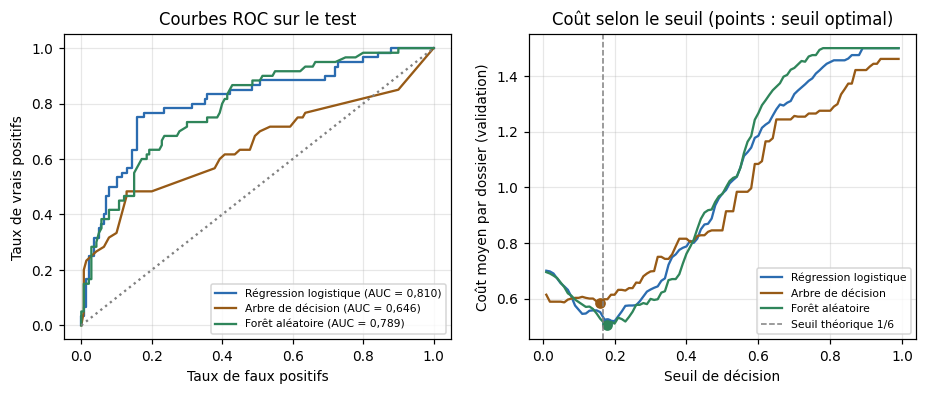

In [15]:
# Figure 3 : courbes ROC sur le test, et coût selon le seuil (validation)
couleurs = {'lr': '#2b6cb0', 'dt': '#975a16', 'rf': '#2f855a'}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for k in modeles:
    fpr, tpr, _ = roc_curve(y_test, proba_test[k])
    axes[0].plot(fpr, tpr, color=couleurs[k], label='{} (AUC = {})'.format(libelles[k], fr(R['test'][k]['AUC'], 3)))
    c = courbe_cout(y_app, oof[k]) / len(y_app)
    axes[1].plot(SEUILS, c, color=couleurs[k], label=libelles[k])
    axes[1].plot(R['val'][k]['seuil'], c[list(SEUILS).index(R['val'][k]['seuil'])], 'o', color=couleurs[k])
axes[0].plot([0, 1], [0, 1], ':', color='grey')
axes[0].set_xlabel('Taux de faux positifs'); axes[0].set_ylabel('Taux de vrais positifs')
axes[0].set_title('Courbes ROC sur le test'); axes[0].legend(fontsize=7, loc='lower right')
axes[1].axvline(COUT_FP / (COUT_FP + COUT_FN), color='grey', ls='--', lw=1, label='Seuil théorique 1/6')
axes[1].set_xlabel('Seuil de décision'); axes[1].set_ylabel('Coût moyen par dossier (validation)')
axes[1].set_title('Coût selon le seuil (points : seuil optimal)'); axes[1].legend(fontsize=7)
fig.savefig(FIGURES / 'fig3_roc_et_cout.png', dpi=200, bbox_inches='tight')
plt.show()

In [16]:
# Matrice de confusion du modèle retenu, avec son seuil
k = R['retenu']
cm = confusion_matrix(y_test, (proba_test[k] >= R['val'][k]['seuil']).astype(int), labels=[0, 1])
R['confusion'] = {'VN': int(cm[0, 0]), 'FP': int(cm[0, 1]), 'FN': int(cm[1, 0]), 'VP': int(cm[1, 1])}
print('Modèle retenu :', libelles[k], '| seuil', fr(R['val'][k]['seuil'], 2))
display(pd.DataFrame(cm, index=['Réel : bon', 'Réel : mauvais'], columns=['Prédit : accepté', 'Prédit : refusé']))
print('Coût final :', R['test'][k]['cout'], '(accepter tous :', R['naif_test']['accepter_tous'],
      '| refuser tous :', R['naif_test']['refuser_tous'], ')')

Modèle retenu : Forêt aléatoire | seuil 0,18


,Prédit : accepté,Prédit : refusé
Réel : bon,51,89
Réel : mauvais,4,56


Coût final : 109 (accepter tous : 300 | refuser tous : 140 )


In [17]:
# Incertitude : avec 200 dossiers, le résultat est bruité. Intervalle de confiance bootstrap de la différence de coût
# entre le modèle retenu et la meilleure référence naïve (coût moyen par dossier ; négatif = le modèle gagne)
rng = np.random.default_rng(GRAINE)
yt = y_test.to_numpy()
pred = (proba_test[R['retenu']] >= R['val'][R['retenu']]['seuil']).astype(int)
c_modele = COUT_FP * ((pred == 1) & (yt == 0)) + COUT_FN * ((pred == 0) & (yt == 1))
if R['naif_test']['accepter_tous'] <= R['naif_test']['refuser_tous']:
    c_naif = COUT_FN * (yt == 1)
else:
    c_naif = COUT_FP * (yt == 0)
diffs = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    diffs.append(c_modele[i].mean() - c_naif[i].mean())
R['bootstrap_diff'] = [float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))]
print('Différence de coût moyen par dossier (modèle - meilleure référence), IC à 95 % :',
      [fr(v, 2) for v in R['bootstrap_diff']])

Différence de coût moyen par dossier (modèle - meilleure référence), IC à 95 % : ['-0,27', '-0,04']


,Coût d'un faux négatif,Seuil théorique 1/(1+c),Seuil optimal (validation),Coût test (modèle),Accepter tous,Refuser tous
0,3,0.25,0.23,91,180,140
1,5,0.17,0.18,109,300,140
2,10,0.09,0.17,132,600,140


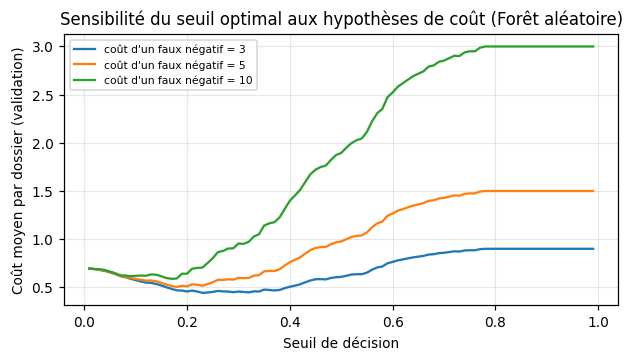

In [18]:
# Analyse de sensibilité : le seuil optimal dépend du coût d'un faux négatif (accepter un mauvais client)
lignes, courbes = [], {}
p_oof, p_te = oof[R['retenu']], proba_test[R['retenu']]
for c_fn in (3, 5, 10):
    s = meilleur_seuil(y_app, p_oof, c_fn=c_fn)
    courbes[c_fn] = courbe_cout(y_app, p_oof, c_fn=c_fn) / len(y_app)
    c_te = cout(y_test, (p_te >= s).astype(int), c_fn=c_fn)
    lignes.append({'Coût d\'un faux négatif': c_fn, 'Seuil théorique 1/(1+c)': round(1 / (1 + c_fn), 2),
                   'Seuil optimal (validation)': s, 'Coût test (modèle)': int(c_te),
                   'Accepter tous': c_fn * n_mauvais_test, 'Refuser tous': COUT_FP * n_bon_test})
sens = pd.DataFrame(lignes)
R['sensibilite'] = sens.to_dict(orient='records')
display(sens)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for c_fn, c in courbes.items():
    ax.plot(SEUILS, c, label='coût d\'un faux négatif = {}'.format(c_fn))
ax.set_xlabel('Seuil de décision'); ax.set_ylabel('Coût moyen par dossier (validation)')
ax.set_title('Sensibilité du seuil optimal aux hypothèses de coût ({})'.format(libelles[R['retenu']]))
ax.legend(fontsize=7)
fig.savefig(FIGURES / 'fig4_sensibilite.png', dpi=200, bbox_inches='tight')
plt.show()

In [19]:
# Analyse des erreurs : qui le modèle rate-t-il ? (modèle retenu, seuil retenu, jeu de test)
k = R['retenu']; s = R['val'][k]['seuil']
test = df.loc[X_test.index].assign(score=proba_test[k])
test['refuse'] = (test['score'] >= s).astype(int)
faux_neg = test[(test['cible'] == 1) & (test['refuse'] == 0)]
faux_pos = test[(test['cible'] == 0) & (test['refuse'] == 1)]
R['erreurs'] = {'faux_negatifs': int(len(faux_neg)), 'faux_positifs': int(len(faux_pos)),
                'taux_refus': float(test['refuse'].mean()),
                'compte_faux_neg': faux_neg['checking_status'].value_counts().to_dict()}
print('Taux de refus global : {} % des dossiers'.format(fr(R['erreurs']['taux_refus'] * 100)))
print('Mauvais risques acceptés à tort, par situation de compte :', R['erreurs']['compte_faux_neg'])
print('Taux de mauvais risques refusés selon le compte (%) :',
      (test[test['cible'] == 1].groupby('checking_status')['refuse'].mean() * 100).round(0).to_dict())

Taux de refus global : 72,5 % des dossiers
Mauvais risques acceptés à tort, par situation de compte : {'A14': 3, 'A12': 1}
Taux de mauvais risques refusés selon le compte (%) : {'A11': 100.0, 'A12': 95.0, 'A13': 100.0, 'A14': 62.0}


In [20]:
# Importance des variables par permutation (sur le test, métrique AUC) pour le modèle retenu
imp = permutation_importance(finaux[R['retenu']], X_test, y_test, scoring='roc_auc', n_repeats=20,
                             random_state=GRAINE, n_jobs=-1)
importance = pd.DataFrame({'variable': X_test.columns, 'baisse_AUC': imp.importances_mean,
                           'ecart_type': imp.importances_std}).sort_values('baisse_AUC', ascending=False).round(4)
R['importance'] = importance.head(5).to_dict(orient='records')
importance.head(8)

,variable,baisse_AUC,ecart_type
0,checking_status,0.1209,0.0325
3,purpose,0.0200,0.0083
1,duration,0.0188,0.0118
4,credit_amount,0.0181,0.0080
9,other_parties,0.0086,0.0045
5,savings_status,0.0076,0.0091
2,credit_history,0.0075,0.0138
18,own_telephone,0.0062,0.0044


In [21]:
# Illustration : 5 dossiers du jeu de test, jamais vus à l'apprentissage
choix = [test['score'].idxmax()]
if len(faux_neg): choix.append(faux_neg['score'].idxmin())
if len(faux_pos): choix.append(faux_pos['score'].idxmax())
choix.append(test['score'].sub(test['score'].median()).abs().idxmin())
choix.append(test['score'].idxmin())
choix = list(dict.fromkeys(choix))
test.loc[choix, ['checking_status', 'duration', 'credit_amount', 'age', 'purpose', 'score', 'refuse', 'cible']].round({'score': 3})

,checking_status,duration,credit_amount,age,purpose,score,refuse,cible
522,A11,48,7119,53,A42,0.797,1,1
228,A14,9,1478,22,A43,0.060,0,1
678,A11,24,2384,64,A43,0.713,1,0
587,A11,12,1289,21,A42,0.290,1,0
234,A14,4,1544,42,A43,0.003,0,0


**Comment lire ces résultats.** Le tableau de synthèse donne, pour chaque modèle et chaque référence naïve, le nombre d'erreurs de chaque type et leur coût. La colonne « Coût (seuil 0,5) » permet de voir ce que l'optimisation du seuil change réellement. L'intervalle bootstrap indique si l'avantage sur la meilleure référence naïve est solide ou noyé dans le bruit d'un test de 200 dossiers. L'analyse de sensibilité montre que le seuil optimal baisse quand les faux négatifs coûtent plus cher. L'importance par permutation décrit des **associations**, pas des causes. Les commentaires chiffrés sont dans la section 10, générés à partir de vos résultats.

## 10. Discussion des résultats

In [22]:
k = R['retenu']; t = R['test'][k]; v = R['val'][k]
red = (R['meilleur_naif'] - t['cout']) / R['meilleur_naif']
atteint = red >= 0.10
meilleur_nom = 'accepter tous' if R['naif_test']['accepter_tous'] <= R['naif_test']['refuser_tous'] else 'refuser tous'
couts_test = {kk: R['test'][kk]['cout'] for kk in modeles}
rang = sorted(couts_test, key=couts_test.get)
auc_app = float(roc_auc_score(y_app, finaux[k].predict_proba(X_app)[:, 1]))
solide = R['bootstrap_diff'][1] < 0
txt_ic = 'statistiquement net' if solide else "à relativiser, car l'intervalle contient 0 ou reste proche de 0"
txt_seuil = 'proches' if abs(v['seuil'] - 1/6) <= 0.1 else 'éloignés, ce qui suggère des probabilités mal calibrées'
txt_rang = ('Le classement du test confirme le choix fait en validation.' if rang[0] == k else
            "Le classement du test diffère du choix fait en validation : avec 200 dossiers, les écarts de coût entre modèles sont du même ordre que le bruit, et le test ne sert pas à choisir le modèle.")
txt_sur = ('Un grand écart entre apprentissage et validation signale du surapprentissage.' if auc_app - v['auc_cv'] > 0.1
           else "L'écart entre apprentissage et validation est modéré.")
txt_atteint = 'atteint' if atteint else 'non atteint'
imp_noms = ', '.join('`{}`'.format(d['variable']) for d in R['importance'][:3])
texte = f"""
**Réponse à l'objectif.** L'objectif est **{txt_atteint}** : le modèle retenu ({libelles[k]}, seuil {fr(t['seuil'], 2)}) a un coût de test de {t['cout']}, contre {R['meilleur_naif']} pour la meilleure référence naïve ({meilleur_nom}), soit une réduction de {fr(red * 100)} % pour un objectif de 10 %. L'intervalle de confiance à 95 % de la différence de coût par dossier est [{fr(R['bootstrap_diff'][0], 2)} ; {fr(R['bootstrap_diff'][1], 2)}] : l'avantage est {txt_ic} avec seulement {R['n_test']} dossiers de test.

**Interprétation.** Au seuil théorique de 1/6 ({fr(1/6, 2)}), le seuil trouvé par validation est {fr(v['seuil'], 2)} : les deux sont {txt_seuil}. Le seuil optimal est bien inférieur à 0,5 : pour limiter les faux négatifs (coût 5), la banque accepte de refuser {R['erreurs']['faux_positifs']} bons clients ({fr(R['erreurs']['taux_refus'] * 100)} % de refus au total). Avec le seuil de 0,5, le coût de test du même modèle serait de {t['cout_05']}. Variables les plus influentes : {imp_noms}.

**Comparaison des modèles.** Classement par coût de test : {', '.join('{} ({})'.format(libelles[kk], couts_test[kk]) for kk in rang)}. {txt_rang}

**Surapprentissage et généralisation.** AUC du modèle retenu : {fr(auc_app, 3)} sur l'apprentissage, {fr(v['auc_cv'], 3)} en validation croisée, {fr(t['AUC'], 3)} sur le test. {txt_sur}
"""
display(Markdown(texte))


**Réponse à l'objectif.** L'objectif est **atteint** : le modèle retenu (Forêt aléatoire, seuil 0,18) a un coût de test de 109, contre 140 pour la meilleure référence naïve (refuser tous), soit une réduction de 22,1 % pour un objectif de 10 %. L'intervalle de confiance à 95 % de la différence de coût par dossier est [-0,27 ; -0,04] : l'avantage est statistiquement net avec seulement 200 dossiers de test.

**Interprétation.** Au seuil théorique de 1/6 (0,17), le seuil trouvé par validation est 0,18 : les deux sont proches. Le seuil optimal est bien inférieur à 0,5 : pour limiter les faux négatifs (coût 5), la banque accepte de refuser 89 bons clients (72,5 % de refus au total). Avec le seuil de 0,5, le coût de test du même modèle serait de 187. Variables les plus influentes : `checking_status`, `purpose`, `duration`.

**Comparaison des modèles.** Classement par coût de test : Régression logistique (107), Forêt aléatoire (109), Arbre de décision (160). Le classement du test diffère du choix fait en validation : avec 200 dossiers, les écarts de coût entre modèles sont du même ordre que le bruit, et le test ne sert pas à choisir le modèle.

**Surapprentissage et généralisation.** AUC du modèle retenu : 1,000 sur l'apprentissage, 0,792 en validation croisée, 0,789 sur le test. Un grand écart entre apprentissage et validation signale du surapprentissage.


**Comparaison avec les travaux liés.** Comme Baesens *et al.* [2] et Lessmann *et al.* [3], nous observons que la régression logistique reste une référence difficile à battre sur des jeux de crédit de cette taille, et que des modèles plus flexibles ne garantissent pas un gain. Nos chiffres ne sont toutefois pas comparables aux leurs : métrique différente (coût), jeu unique, test de 200 dossiers.

**Limites et biais.**

- **Petit échantillon.** 1 000 dossiers, 60 mauvais risques dans le test : un seul dossier mal classé fait varier le coût de 1 ou 5. Les résultats dépendent du tirage (graine 42).
- **Coûts supposés.** La matrice 1 / 5 vient de la documentation du jeu ; les vrais coûts d'une banque dépendent du montant du crédit, des garanties et de la marge. L'analyse de sensibilité (3, 5, 10) montre que le seuil change avec cette hypothèse.
- **Références naïves.** Avec une matrice 1 / 5 et 30 % de mauvais risques, « refuser tous » coûte moins cher que « accepter tous », mais ce n'est pas une politique réaliste (la banque n'accorderait plus aucun crédit) : le coût de 1 pour un bon client refusé résume mal le manque à gagner réel.
- **Données anciennes et biais de sélection.** Seuls les dossiers *accordés* ont un résultat observé ; on ignore ce qu'auraient donné les dossiers refusés.
- **Équité.** Le jeu contient des variables sensibles : `age`, `personal_status` (qui mêle sexe et situation familiale) et `foreign_worker`. Un modèle qui les utilise peut discriminer certains groupes, ce qui pose un problème légal et éthique. Cette étude ne mesure pas l'équité entre groupes : c'est une limite à lever avant tout usage réel.
- **Calibration.** Le seuil théorique 1/6 suppose des probabilités bien calibrées ; les arbres et surtout les forêts le sont rarement, d'où l'intérêt d'un seuil propre à chaque modèle.

**Pistes d'amélioration.** (1) Mesurer l'équité (taux d'acceptation par groupe) et tester le modèle sans les variables sensibles. (2) Calibrer les probabilités puis comparer au seuil théorique. (3) Faire dépendre le coût du montant du crédit (`credit_amount`) plutôt qu'un coût fixe.

## 11. Conclusion

In [23]:
k = R['retenu']; t = R['test'][k]
red = (R['meilleur_naif'] - t['cout']) / R['meilleur_naif']
txt_ok = 'atteint' if red >= 0.10 else 'non atteint'
display(Markdown(f"""
À partir des seules informations du dossier, le modèle retenu ({libelles[k]}) réduit le coût des erreurs de {fr(red * 100)} % par rapport à la meilleure référence naïve (coût de test {t['cout']} contre {R['meilleur_naif']}), avec un seuil de décision de {fr(t['seuil'], 2)} et une AUC de {fr(t['AUC'], 3)}. L'objectif de 10 % est {txt_ok}.

L'enseignement principal est que, pour le risque de crédit, **le seuil de décision compte autant que le choix du modèle** : avec les coûts 1 / 5, le seuil par défaut de 0,5 coûterait {t['cout_05']} au lieu de {t['cout']}. Il faut aussi rester prudent : avec 200 dossiers de test, les écarts entre modèles sont fragiles, et les variables sensibles du jeu imposeraient un contrôle d'équité avant tout usage réel.
"""))


À partir des seules informations du dossier, le modèle retenu (Forêt aléatoire) réduit le coût des erreurs de 22,1 % par rapport à la meilleure référence naïve (coût de test 109 contre 140), avec un seuil de décision de 0,18 et une AUC de 0,789. L'objectif de 10 % est atteint.

L'enseignement principal est que, pour le risque de crédit, **le seuil de décision compte autant que le choix du modèle** : avec les coûts 1 / 5, le seuil par défaut de 0,5 coûterait 187 au lieu de 109. Il faut aussi rester prudent : avec 200 dossiers de test, les écarts entre modèles sont fragiles, et les variables sensibles du jeu imposeraient un contrôle d'équité avant tout usage réel.


## 12. Références et citations

1. H. Hofmann, « Statlog (German Credit Data) », UCI Machine Learning Repository, jeu n° 144, 1994, licence CC BY 4.0, https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data, consulté le 24/11/2026.
2. B. Baesens, T. Van Gestel, S. Viaene, M. Stepanova, J. Suykens, J. Vanthienen, « Benchmarking state-of-the-art classification algorithms for credit scoring », *Journal of the Operational Research Society*, vol. 54, n° 6, p. 627-635, 2003.
3. S. Lessmann, B. Baesens, H.-V. Seow, L. C. Thomas, « Benchmarking state-of-the-art classification algorithms for credit scoring: An update of research », *European Journal of Operational Research*, vol. 247, n° 1, p. 124-136, 2015.
4. D. W. Hosmer, S. Lemeshow, R. X. Sturdivant, *Applied Logistic Regression*, 3e éd., Wiley, 2013.
5. L. Breiman, J. Friedman, R. Olshen, C. Stone, *Classification and Regression Trees*, Wadsworth, 1984.
6. L. Breiman, « Random forests », *Machine Learning*, vol. 45, n° 1, p. 5-32, 2001.
7. C. Elkan, « The foundations of cost-sensitive learning », *Proceedings of the 17th International Joint Conference on Artificial Intelligence (IJCAI)*, p. 973-978, 2001.
8. T. Saito, M. Rehmsmeier, « The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets », *PLOS ONE*, vol. 10, n° 3, e0118432, 2015.
9. F. Pedregosa *et al.*, « Scikit-learn: Machine Learning in Python », *Journal of Machine Learning Research*, vol. 12, p. 2825-2830, 2011.
10. Support du cours BD & DS, notebook `Tp_ML.ipynb`, ENCG Settat, 2026.

## 13. Annexes



### A. Déclaration des outils d'IA

| Outil ou ressource | Date | Usage précis | Parties concernées | Vérification effectuée |
| --- | --- | --- | --- | --- |
| ChatGPT (OpenAI) | 17/11/2026 | Compréhension des étapes du projet, aide à l'écriture et à la correction du code, explications sur le prétraitement et les modèles, structuration du rapport  | Code exécuté sur Google Colab ; résultats vérifiés sur le jeu German Credit |



In [24]:
# Enregistrement des résultats et archive téléchargeable
def propre(o):
    if isinstance(o, dict): return {str(k): propre(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [propre(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    return o
with open(BASE / 'resultats.json', 'w', encoding='utf-8') as f:
    json.dump(propre(R), f, ensure_ascii=False, indent=1)
archive = shutil.make_archive('projet_f1_credit', 'zip', BASE)
print('Archive créée :', archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Hors de Colab : récupérez le fichier', archive, 'dans le dossier courant.')

Archive créée : /content/projet_f1_credit.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>